Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\SSC\OneDrive\Desktop\areeba\cleaned_ecommerce_orders.csv")
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,Ord200000,2023-01-04,C72649,Monitor,5.0,570.62,928 Main St,Debit Card,Shipped,Trk37947903,7,Save10,Instagram,2853.10
1,Ord200001,2024-08-23,C75739,Phone,2.0,151.35,823 Main St,Online,Shipped,Trk91186779,3,Save10,Referral,302.70
2,Ord200002,2024-02-27,C81728,Tablet,5.0,550.68,512 Main St,Credit Card,Cancelled,Trk42903982,8,Freeship,Email,2753.40
3,Ord200003,2023-10-15,C33540,Chair,1.0,273.19,275 Main St,Debit Card,Returned,Trk62788070,5,Save10,Facebook,273.19
4,Ord200004,2025-05-08,C81840,Printer,4.0,626.01,668 Main St,Online,Delivered,Trk29241424,8,Save10,Email,2504.04


Understand your dataset

In [2]:
df.shape

(1200, 14)

In [4]:
df.columns

Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='str')

In [5]:
#Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   str    
 1   Date             1200 non-null   str    
 2   CustomerID       1200 non-null   str    
 3   Product          1200 non-null   str    
 4   Quantity         1200 non-null   float64
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   str    
 7   PaymentMethod    1200 non-null   str    
 8   OrderStatus      1200 non-null   str    
 9   TrackingNumber   1200 non-null   str    
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       1200 non-null   str    
 12  ReferralSource   1200 non-null   str    
 13  TotalPrice       1200 non-null   float64
dtypes: float64(3), int64(1), str(10)
memory usage: 131.4 KB


In [6]:
#Check missing values
df.isnull().sum()

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64

Calculate basic statistics

In [7]:
#Basic Statistical summary
df.describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [ ]:
#mean
df.select_dtypes(include="number").mean()

Quantity          2.945833
UnitPrice       356.412750
ItemsInCart       5.485000
TotalPrice     1053.968300
dtype: float64

In [16]:
#median
df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].median()

Quantity         3.000
UnitPrice      364.210
ItemsInCart      5.000
TotalPrice     823.615
dtype: float64

In [17]:
#count
df.count()

OrderID            1200
Date               1200
CustomerID         1200
Product            1200
Quantity           1200
UnitPrice          1200
ShippingAddress    1200
PaymentMethod      1200
OrderStatus        1200
TrackingNumber     1200
ItemsInCart        1200
CouponCode         1200
ReferralSource     1200
TotalPrice         1200
dtype: int64

In [18]:
df["OrderID"].nunique()

1200

Identify Trends

In [19]:
df["CustomerID"].nunique()

1189

Calculate complete statistical summary

In [20]:
df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [21]:
df["Product"].value_counts().head(10)

Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64

In [22]:
df["PaymentMethod"].value_counts()

PaymentMethod
Online         258
Cash           246
Credit Card    234
Debit Card     232
Gift Card      230
Name: count, dtype: int64

In [23]:
df["OrderStatus"].value_counts()

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64

In [24]:
df["ReferralSource"].value_counts()

ReferralSource
Instagram    259
Email        250
Google       241
Facebook     228
Referral     222
Name: count, dtype: int64

Analyze monthly sales trends

In [25]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [26]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["TotalPrice"].sum()

monthly_sales

Month
2023-01    56685.75
2023-02    40117.66
2023-03    48609.37
2023-04    27751.71
2023-05    63836.84
2023-06    49500.19
2023-07    42820.66
2023-08    54352.14
2023-09    29526.67
2023-10    52607.85
2023-11    43079.67
2023-12    43754.73
2024-01    38528.08
2024-02    36909.57
2024-03    36030.90
2024-04    49613.14
2024-05    27909.11
2024-06    68068.54
2024-07    42963.98
2024-08    31991.07
2024-09    39794.98
2024-10    37226.97
2024-11    32413.76
2024-12    38785.77
2025-01    29099.40
2025-02    35317.55
2025-03    39200.66
2025-04    31821.20
2025-05    43396.64
2025-06    53047.40
Freq: M, Name: TotalPrice, dtype: float64

In [27]:
df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


Monthly sales trend

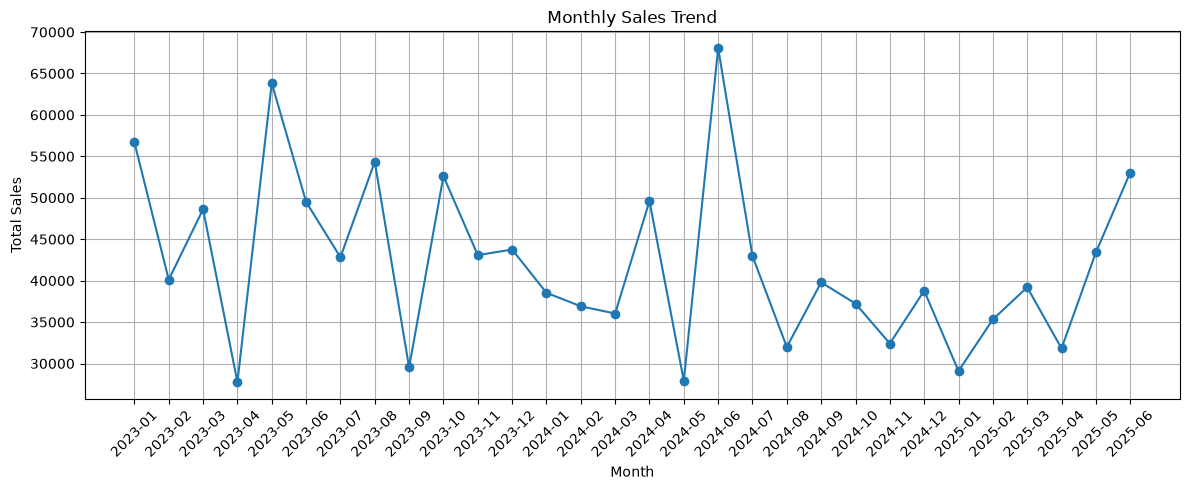

In [28]:
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["TotalPrice"].sum()

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.grid()
plt.tight_layout()
plt.show()

Top 10 products

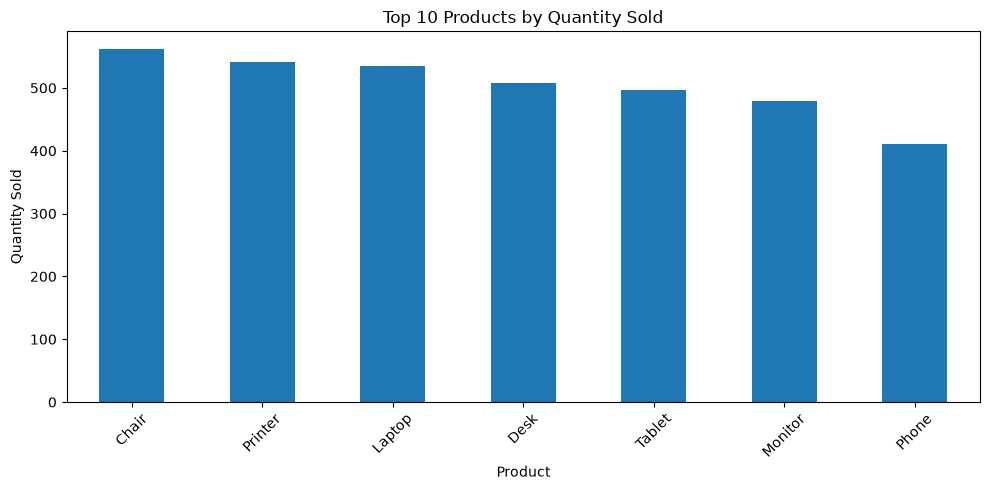

In [30]:
top_products = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
top_products.plot(kind="bar")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Payment methods

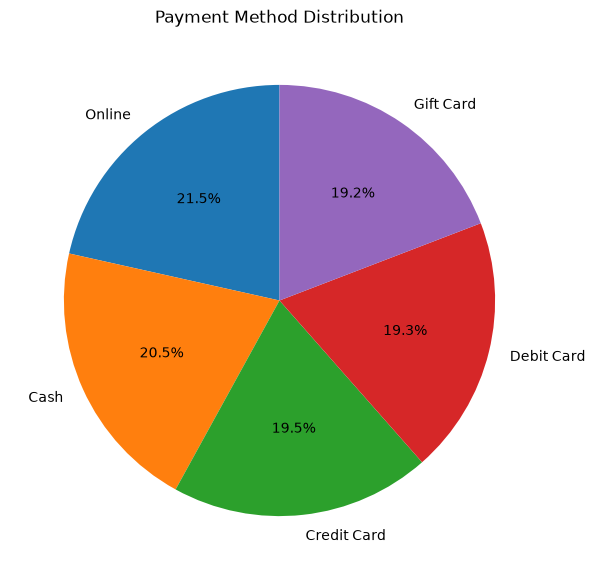

In [32]:
payment_counts = df["PaymentMethod"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct="%1.1f%%",
        startangle=90)

plt.title("Payment Method Distribution")

plt.show()

Order status

In [ ]:
order_status = df["OrderStatus"].value_counts()

plt.figure(figsize=(8, 5))

order_status.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Total price distribution

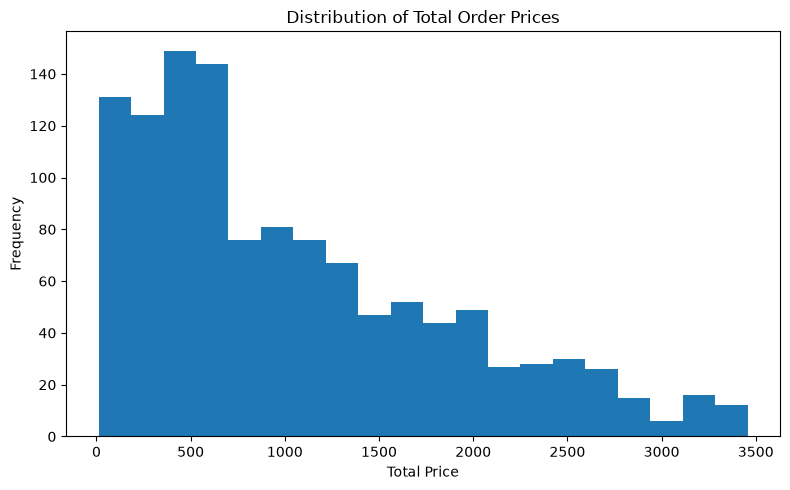

In [33]:
plt.figure(figsize=(8, 5))

plt.hist(df["TotalPrice"].dropna(), bins=20)

plt.title("Distribution of Total Order Prices")
plt.xlabel("Total Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Outlier detection

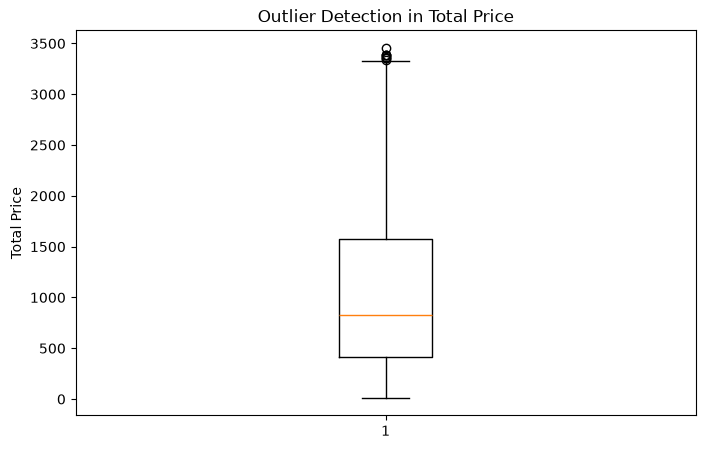

In [34]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["TotalPrice"].dropna())

plt.title("Outlier Detection in Total Price")
plt.ylabel("Total Price")

plt.show()